# 02 Multiple Linear Regression
ใช้ทั้ง 20 feature: `int.rate = θ0 + θ1x1 + ... + θ20x20`
scale ทุก feature ด้วยค่าจาก train แล้วเทรนด้วย gradient descent (lr 0.1, 2,000 รอบ)

โค้ด: `Model/Regression/MultipleRegression.py`  
ผลลัพธ์: `Results/Regression/02_Multiple_Linear_Regression/`

## 1. เตรียมข้อมูล

In [1]:
import os
import sys

sys.path.insert(0, os.path.abspath(os.path.join("..", "..", "Model", "Common")))

from project import Outputs, regression_data
from model_zoo import RegressionPipeline, check_settings
from report_regression import report_regressor
import pandas as pd
from MultipleRegression import MultipleRegressionScratch
from sklearn.linear_model import LinearRegression
import plots

out = Outputs("Regression", "02_Multiple_Linear_Regression")
d = regression_data()
print(f"train {d.X_train.shape} | test {d.X_test.shape} | target int.rate | {len(d.feature_cols)} features")

train (7662, 20) | test (1916, 20) | target int.rate | 20 features


## 2. เทรนโมเดล

In [2]:
model = RegressionPipeline(MultipleRegressionScratch(learning_rate=0.1, n_iterations=2000))
check_settings("2. Multiple Linear", model)
model.fit(d.X_train, d.y_train, d.feature_cols)

sk = LinearRegression().fit(d.X_train, d.y_train)
sk_r2 = sk.score(d.X_test, d.y_test)

settings match Common/model_zoo.py (7 values checked)


## 3. ผลลัพธ์

Train loss (MSE)   0.000241
Test loss (MSE)    0.000230
Test RMSE          0.015181
Test MAE           0.011411
Test R2            0.665245
scikit-learn R2    0.664842
Difference         0.000403

scratch vs scikit-learn LinearRegression: R2 0.6652 vs 0.6648 (difference +0.0004)


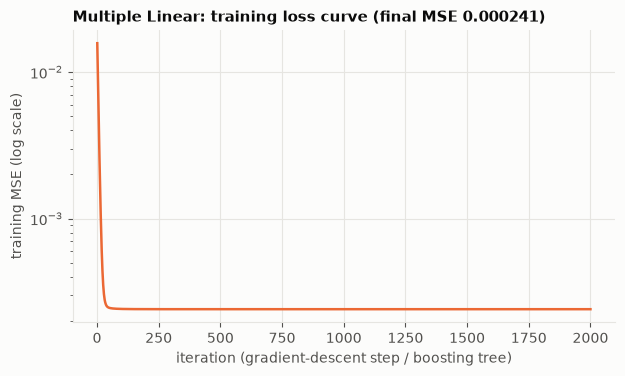

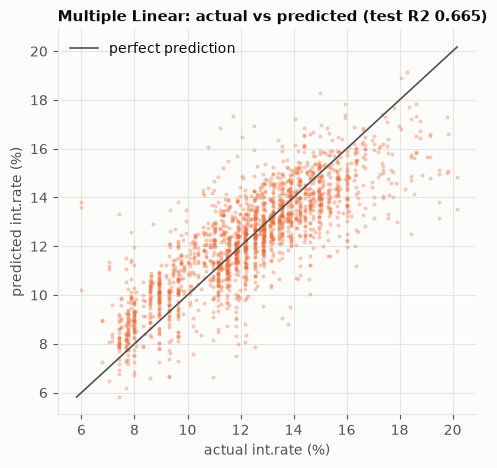

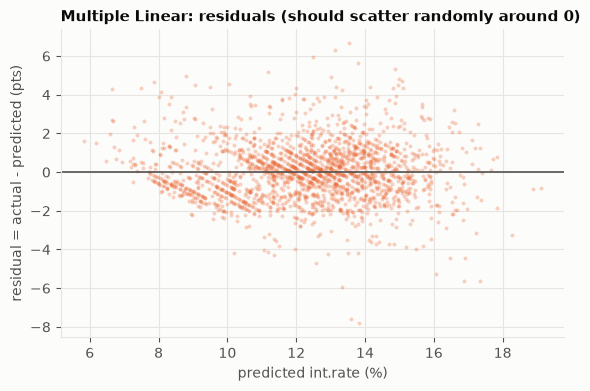

saved + reloaded Results/Regression/02_Multiple_Linear_Regression/model.joblib (identical predictions: True)

|coefficient| per 1 SD of the feature (top 8):
fico                      0.018813
installment               0.009593
purpose_small_business    0.003946
high_revol_util           0.002880
inq.last.6mths            0.001365
purpose_credit_card       0.001248
credit.policy             0.001197
log.annual.inc            0.001040


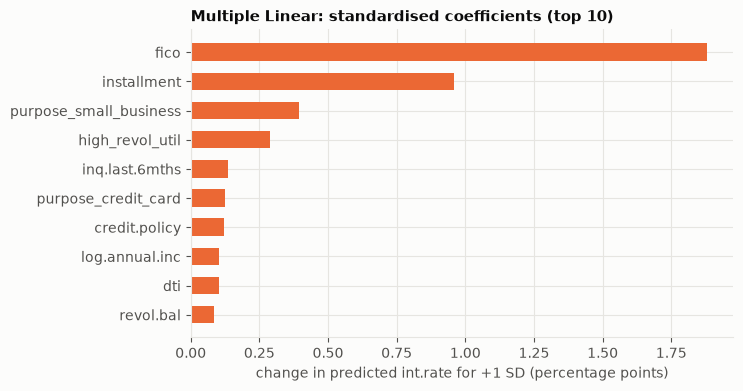

In [3]:
row = report_regressor(
    out, "2. Multiple Linear", model, d, model.model.loss_history, (sk_r2, "scikit-learn LinearRegression")
)

imp = pd.Series(model.model.standardized_importance(model.transform(d.X_train)), index=d.feature_cols)
imp = imp.sort_values(ascending=False)
imp.rename("abs_coef_per_1SD").to_csv(out.table("feature_importance.csv"), index_label="feature")
print("\n|coefficient| per 1 SD of the feature (top 8):")
print(imp.head(8).to_string())
fig, ax = plots.plt.subplots(figsize=(7, 4))
top = imp.head(10)[::-1]
ax.barh(top.index, top.values * 100, color=plots.MODEL_COLORS["2. Multiple Linear"], height=0.6)
ax.set_xlabel("change in predicted int.rate for +1 SD (percentage points)")
ax.set_title("Multiple Linear: standardised coefficients (top 10)")
plots._save(fig, out.image("feature_importance.png"))